In [2]:
import time
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0)
np.random.seed(0)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Urządzenie: {DEVICE}')

Urządzenie: cpu


In [3]:
def gen_delayed(N, L):
    val = np.random.rand(N, L, 1).astype(np.float32)
    mark = np.zeros((N, L, 1), np.float32)
    y = np.zeros((N, 1), np.float32)
    for i in range(N):
        p = np.random.choice(np.arange(8, L), 2, replace=False)
        mark[i, p, 0] = 1.0
        y[i, 0] = val[i, p - 8, 0].sum()
    x = np.concatenate([val, mark], axis=2)
    return torch.tensor(x).to(DEVICE), torch.tensor(y).to(DEVICE)

xx, yy = gen_delayed(1, 20)
xx_np, yy_np = xx.cpu().numpy(), yy.cpu().numpy()
poz = np.where(xx_np[0, :, 1] == 1)[0]
wartosci_wskazywane = xx_np[0, poz - 8, 0]

print("ZADANIE 1: TEST GENERATORA")
print(f"Pozycje znaczników (kroki 1-based): {poz + 1}")
print(f"Pozycje wartości (kroki 1-based): {poz - 7}")
print(f"Wskazane wartości w kanałach: {wartosci_wskazywane}")
print(f"Suma obliczona ręcznie: {wartosci_wskazywane.sum():.4f} | Cel (y): {yy_np[0, 0]:.4f}\n")

ZADANIE 1: TEST GENERATORA
Pozycje znaczników (kroki 1-based): [13 18]
Pozycje wartości (kroki 1-based): [ 5 10]
Wskazane wartości w kanałach: [0.4236548 0.3834415]
Suma obliczona ręcznie: 0.8071 | Cel (y): 0.8071



In [4]:
class RNNNet(nn.Module):
    def __init__(self, typ, hidden=32):
        super().__init__()
        self.rnn = {'RNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}[typ](2, hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)
    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :]) 

class ConvNetDilated(nn.Module):
    def __init__(self, ch=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(2, ch, 3, padding=1, dilation=1), nn.ReLU(),
            nn.Conv1d(ch, ch, 3, padding=2, dilation=2), nn.ReLU(),
            nn.Conv1d(ch, ch, 3, padding=4, dilation=4), nn.ReLU()
        )
        self.fc = nn.Linear(ch, 1)
    def forward(self, x):
        h = self.net(x.transpose(1, 2)).mean(dim=2)
        return self.fc(h)

class ConvNetNoDilation(nn.Module):
    def __init__(self, ch=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(2, ch, 3, padding=1, dilation=1), nn.ReLU(),
            nn.Conv1d(ch, ch, 3, padding=1, dilation=1), nn.ReLU(),
            nn.Conv1d(ch, ch, 3, padding=1, dilation=1), nn.ReLU()
        )
        self.fc = nn.Linear(ch, 1)
    def forward(self, x):
        h = self.net(x.transpose(1, 2)).mean(dim=2)
        return self.fc(h)

def licz_parametry(m): 
    return sum(p.numel() for p in m.parameters())

In [5]:
def trenuj_wspolne(model, Xtr, Ytr, Xte, Yte, epoki=30, lr=5e-3, batch=128):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    Lf = nn.MSELoss()
    N = len(Xtr)
    
    if DEVICE == 'cuda': torch.cuda.synchronize()
    t0 = time.time()
    
    for ep in range(epoki):
        model.train()
        perm = torch.randperm(N)
        for i in range(0, N, batch):
            idx = perm[i:i+batch]
            opt.zero_grad()
            loss = Lf(model(Xtr[idx]), Ytr[idx])
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            
    if DEVICE == 'cuda': torch.cuda.synchronize()
    czas = time.time() - t0
    
    model.eval()
    with torch.no_grad():
        mse = Lf(model(Xte), Yte).item()
    return mse, czas, model

wyniki = {}
modele_L100 = {} 
Xte_L100, Yte_L100 = None, None

for L in [50, 100]:
    print(f"TRENING DLA L = {L}")
    Xtr, Ytr = gen_delayed(4000, L)
    Xte, Yte = gen_delayed(800, L)
    if L == 100: 
        Xte_L100, Yte_L100 = Xte, Yte
    
    baseline_pred = Ytr.mean().item()
    baseline_mse = ((Yte.cpu().numpy() - baseline_pred)**2).mean()
    print(f"{'Baseline':15s} | MSE: {baseline_mse:.4f} | (stała predykcja: {baseline_pred:.4f})")
    wyniki[f'Baseline_{L}'] = {'mse': baseline_mse, 'czas': 0, 'params': 0}
    
    modele = {
        'SimpleRNN': RNNNet('RNN', hidden=32),
        'LSTM': RNNNet('LSTM', hidden=32),
        'GRU': RNNNet('GRU', hidden=32),
        'Conv1D_Dilated': ConvNetDilated(ch=64)
    }
    
    if L == 100:
        modele['SimpleRNN_64'] = RNNNet('RNN', hidden=64)
        modele['Conv1D_NoDil'] = ConvNetNoDilation(ch=64)
        
    for nazwa, m in modele.items():
        mse, czas, trained_model = trenuj_wspolne(m, Xtr, Ytr, Xte, Yte)
        params = licz_parametry(m)
        wyniki[f'{nazwa}_{L}'] = {'mse': mse, 'czas': czas, 'params': params}
        if L == 100: 
            modele_L100[nazwa] = trained_model
        print(f"{nazwa:15s} | MSE: {mse:.4f} | Czas: {czas:.2f}s | Params: {params}")
    print("")

TRENING DLA L = 50
Baseline        | MSE: 0.1598 | (stała predykcja: 1.0039)
SimpleRNN       | MSE: 0.1598 | Czas: 2.57s | Params: 1185
LSTM            | MSE: 0.1597 | Czas: 7.88s | Params: 4641
GRU             | MSE: 0.1439 | Czas: 5.93s | Params: 3489
Conv1D_Dilated  | MSE: 0.1555 | Czas: 26.46s | Params: 25217

TRENING DLA L = 100
Baseline        | MSE: 0.1667 | (stała predykcja: 0.9943)
SimpleRNN       | MSE: 0.1703 | Czas: 4.72s | Params: 1185
LSTM            | MSE: 0.1667 | Czas: 14.21s | Params: 4641
GRU             | MSE: 0.1663 | Czas: 11.83s | Params: 3489
Conv1D_Dilated  | MSE: 0.1643 | Czas: 34.70s | Params: 25217
SimpleRNN_64    | MSE: 0.1697 | Czas: 5.86s | Params: 4417
Conv1D_NoDil    | MSE: 0.1641 | Czas: 43.14s | Params: 25217



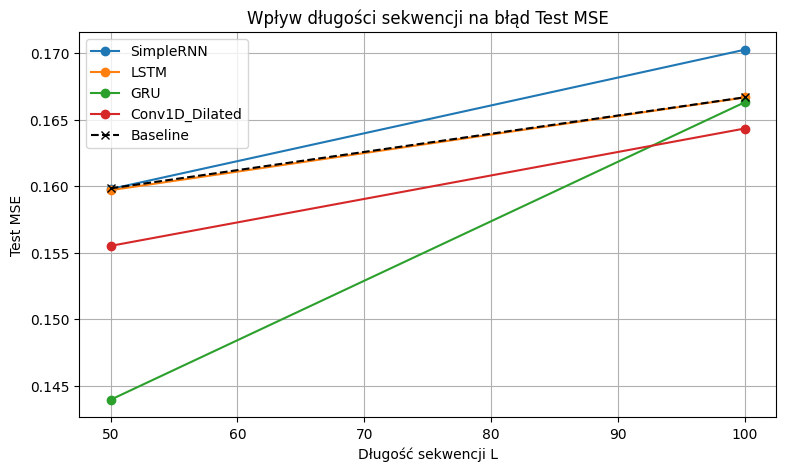

ZADANIE 4: PRZYKŁAD Z DUŻYM BŁĘDEM (SimpleRNN L=100)
Kroki znaczników (numerowane od 1): [10 66]
Kroki wskazanych wartości: [ 2 58]
Wskazane wartości: [0.97497475 0.98591834]
Prawdziwa suma: 1.9609 | Predykcja: 0.9421 | Błąd bezwzględny: 1.0188


In [6]:
L_vals = [50, 100]
archs = ['SimpleRNN', 'LSTM', 'GRU', 'Conv1D_Dilated']
plt.figure(figsize=(9, 5))

for arch in archs:
    mses = [wyniki[f'{arch}_{l}']['mse'] for l in L_vals]
    plt.plot(L_vals, mses, marker='o', label=arch)
    
baseline_mses = [wyniki[f'Baseline_{l}']['mse'] for l in L_vals]
plt.plot(L_vals, baseline_mses, marker='x', linestyle='--', color='black', label='Baseline')

plt.title("Wpływ długości sekwencji na błąd Test MSE")
plt.xlabel("Długość sekwencji L")
plt.ylabel("Test MSE")
plt.legend()
plt.grid(True)
plt.savefig('wykres_modele.png')
plt.show()

bad_model = modele_L100['SimpleRNN']
bad_model.eval()
with torch.no_grad():
    preds = bad_model(Xte_L100)
errors = (preds - Yte_L100).abs().squeeze().cpu().numpy()
w_idx = np.argmax(errors)
w_x = Xte_L100[w_idx].cpu().numpy()
w_y = Yte_L100[w_idx].cpu().numpy()
w_pred = preds[w_idx].cpu().numpy()

poz_w = np.where(w_x[:, 1] == 1)[0]
val_w = w_x[poz_w - 8, 0]

print("ZADANIE 4: PRZYKŁAD Z DUŻYM BŁĘDEM (SimpleRNN L=100)")
print(f"Kroki znaczników (numerowane od 1): {poz_w + 1}")
print(f"Kroki wskazanych wartości: {poz_w - 7}")
print(f"Wskazane wartości: {val_w}")
print(f"Prawdziwa suma: {w_y[0]:.4f} | Predykcja: {w_pred[0]:.4f} | Błąd bezwzględny: {errors[w_idx]:.4f}")